In [1]:

!nvidia-smi
!pip install -q ultralytics


Sun Oct 25 18:41:19 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   36C    P8              9W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:

!pip install -q ultralytics


In [3]:

import torch
import ultralytics

print("PyTorch version:", torch.__version__)
print("Ultralytics version:", ultralytics.__version__)
print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))


Creating new Ultralytics Settings v0.0.8 file ✅ 
View Ultralytics Settings with 'yolo settings' or at '/root/.config/Ultralytics/settings.json'
Update Settings with 'yolo settings key=value', i.e. 'yolo settings runs_dir=path/to/dir'. For help see https://docs.ultralytics.com/usage/settings.
PyTorch version: 2.11.0+cu130
Ultralytics version: 8.4.189
GPU available: True
GPU name: Tesla T4


In [4]:

import os
import zipfile

zip_path = "/content/MangoYOLO.zip"

print("ZIP exists:", os.path.exists(zip_path))

with zipfile.ZipFile(zip_path, "r") as z:
    print("Number of files:", len(z.namelist()))
    for name in z.namelist()[:25]:
        print(name)


ZIP exists: True
Number of files: 3474
MangoYOLO/
VOCDevkit/
VOCDevkit/VOC2007/
VOCDevkit/VOC2007/Annotations/
VOCDevkit/VOC2007/Annotations/gear10n_(1)_01_01.xml
VOCDevkit/VOC2007/Annotations/gear10n_(1)_02_02.xml
VOCDevkit/VOC2007/Annotations/gear10n_(10)_02_04.xml
VOCDevkit/VOC2007/Annotations/gear10n_(10)_03_02.xml
VOCDevkit/VOC2007/Annotations/gear10n_(10)_04_03.xml
VOCDevkit/VOC2007/Annotations/gear10n_(11)_03_02.xml
VOCDevkit/VOC2007/Annotations/gear10n_(11)_03_03.xml
VOCDevkit/VOC2007/Annotations/gear10n_(11)_04_03.xml
VOCDevkit/VOC2007/Annotations/gear10n_(12)_03_04.xml
VOCDevkit/VOC2007/Annotations/gear10n_(12)_04_01.xml
VOCDevkit/VOC2007/Annotations/gear10n_(12)_04_04.xml
VOCDevkit/VOC2007/Annotations/gear10n_(13)_02_02.xml
VOCDevkit/VOC2007/Annotations/gear10n_(13)_02_03.xml
VOCDevkit/VOC2007/Annotations/gear10n_(13)_02_04.xml
VOCDevkit/VOC2007/Annotations/gear10n_(13)_03_03.xml
VOCDevkit/VOC2007/Annotations/gear10n_(14)_02_01.xml
VOCDevkit/VOC2007/Annotations/gear10n_(14)_

In [5]:

import os
import zipfile
import xml.etree.ElementTree as ET
from pathlib import Path
from collections import Counter

ZIP_PATH = "/content/MangoYOLO.zip"
EXTRACT_DIR = "/content/mangoyolo"

# Extract dataset
with zipfile.ZipFile(ZIP_PATH, "r") as z:
    z.extractall(EXTRACT_DIR)

base = Path(EXTRACT_DIR)

print("=== DATASET FOLDERS ===")
for name in ["JPEGImages", "Annotations", "ImageSets"]:
    matches = list(base.rglob(name))
    print(f"\n{name}:")
    for p in matches[:5]:
        print(" ", p)

# Locate XML annotation files
xml_files = list(base.rglob("*.xml"))
print("\nTotal XML files:", len(xml_files))

# Inspect class names and annotation details
class_counts = Counter()
sample_xml = None
xml_errors = 0

for xml_path in xml_files:
    try:
        root = ET.parse(xml_path).getroot()

        if sample_xml is None:
            sample_xml = root

        for obj in root.findall("object"):
            class_name = obj.findtext("name", default="UNKNOWN").strip()
            class_counts[class_name] += 1

    except Exception:
        xml_errors += 1

print("\n=== OBJECT CLASSES ===")
print(class_counts)
print("XML parsing errors:", xml_errors)

if sample_xml is not None:
    print("\n=== SAMPLE XML DETAILS ===")
    print("Image filename:", sample_xml.findtext("filename"))
    print("Image dimensions:")
    size = sample_xml.find("size")
    if size is not None:
        print(
            size.findtext("width"),
            "x",
            size.findtext("height")
        )

    print("Sample objects:")
    for obj in sample_xml.findall("object")[:5]:
        print(
            "Class:", obj.findtext("name"),
            "| Box:", ET.tostring(
                obj.find("bndbox"), encoding="unicode"
            ) if obj.find("bndbox") is not None else "No box"
        )

# Count available image files
image_files = [
    p for p in base.rglob("*")
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png", ".bmp"}
]

print("\nTotal image files:", len(image_files))
print("Sample image paths:")
for p in image_files[:10]:
    print(" ", p)


=== DATASET FOLDERS ===

JPEGImages:
  /content/mangoyolo/VOCDevkit/VOC2007/JPEGImages

Annotations:
  /content/mangoyolo/VOCDevkit/VOC2007/Annotations

ImageSets:
  /content/mangoyolo/VOCDevkit/VOC2007/ImageSets

Total XML files: 1730

=== OBJECT CLASSES ===
Counter({'M': 15281})
XML parsing errors: 0

=== SAMPLE XML DETAILS ===
Image filename: gear2n_(13)_04_02.png
Image dimensions:
612 x 512
Sample objects:
Class: M | Box: <bndbox>
			<xmin>303</xmin>
			<ymin>121</ymin>
			<xmax>353</xmax>
			<ymax>190</ymax>
		</bndbox>
	
Class: M | Box: <bndbox>
			<xmin>334</xmin>
			<ymin>32</ymin>
			<xmax>389</xmax>
			<ymax>97</ymax>
		</bndbox>
	
Class: M | Box: <bndbox>
			<xmin>354</xmin>
			<ymin>73</ymin>
			<xmax>407</xmax>
			<ymax>138</ymax>
		</bndbox>
	
Class: M | Box: <bndbox>
			<xmin>365</xmin>
			<ymin>125</ymin>
			<xmax>417</xmax>
			<ymax>194</ymax>
		</bndbox>
	

Total image files: 1731
Sample image paths:
  /content/mangoyolo/directory_structure.PNG
  /content/mangoyolo/VO

Matched annotated images: 1730


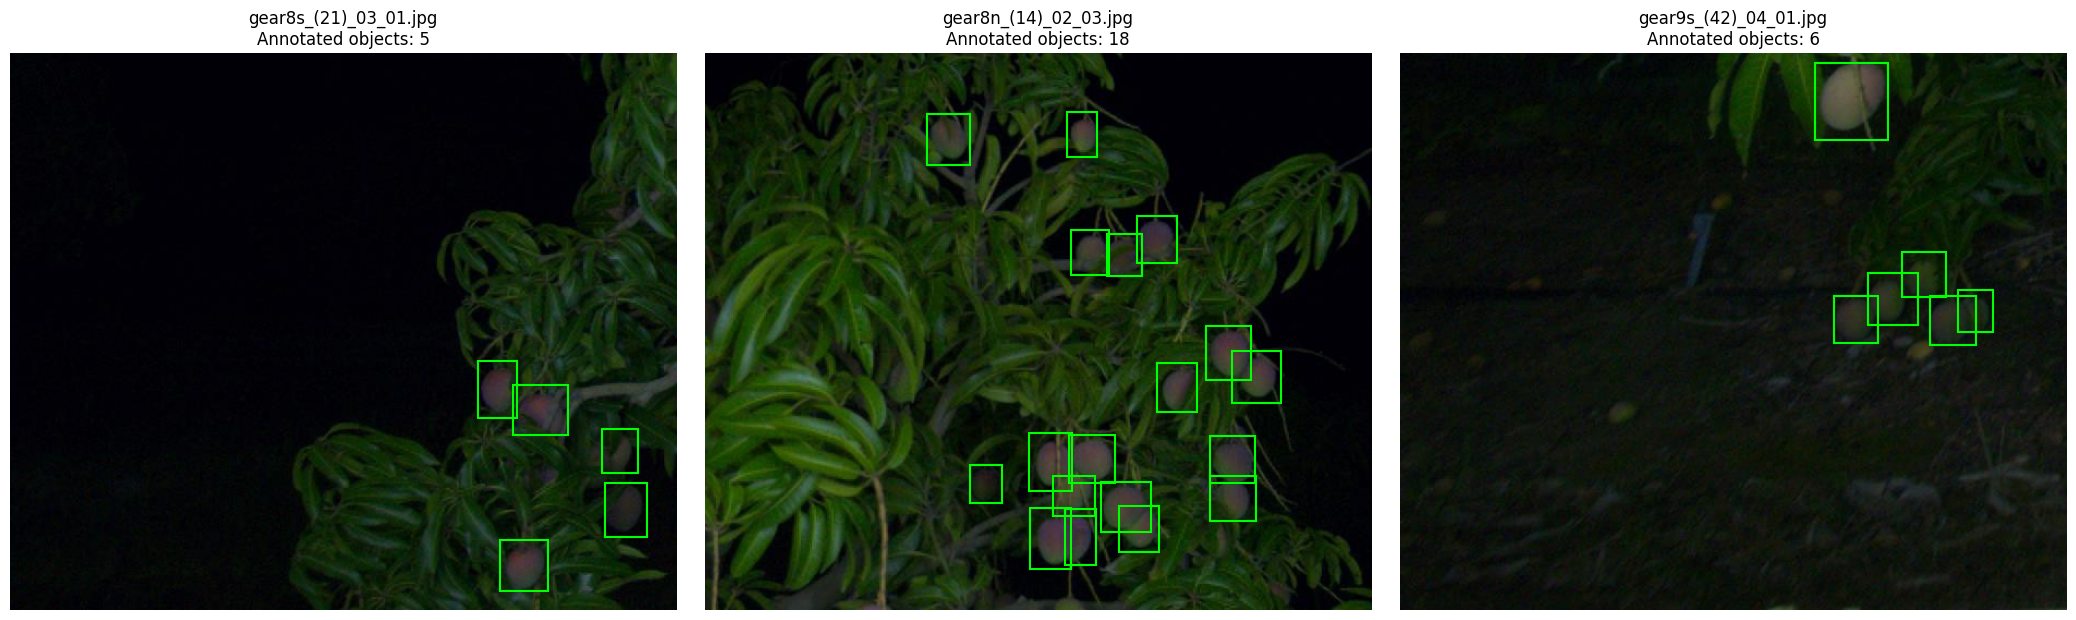

In [6]:

from pathlib import Path
import xml.etree.ElementTree as ET
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
import random

voc_root = Path("/content/mangoyolo/VOCDevkit/VOC2007")
image_dir = voc_root / "JPEGImages"
xml_dir = voc_root / "Annotations"

# Match image files and XML annotations by filename stem.
image_index = {
    p.stem: p for p in image_dir.iterdir()
    if p.is_file() and p.suffix.lower() in
    {".jpg", ".jpeg", ".png"}
}

xml_files = [
    p for p in xml_dir.glob("*.xml")
    if p.stem in image_index
]

print("Matched annotated images:", len(xml_files))

# Show three random annotated images.
samples = random.Random(42).sample(
    xml_files, min(3, len(xml_files))
)

fig, axes = plt.subplots(
    1, len(samples), figsize=(7 * len(samples), 6)
)
if len(samples) == 1:
    axes = [axes]

for ax, xml_path in zip(axes, samples):
    image_path = image_index[xml_path.stem]
    img = Image.open(image_path).convert("RGB")
    root = ET.parse(xml_path).getroot()

    ax.imshow(img)
    count = 0

    for obj in root.findall("object"):
        if obj.findtext("name", "").strip().upper() != "M":
            continue

        box = obj.find("bndbox")
        x1 = float(box.findtext("xmin"))
        y1 = float(box.findtext("ymin"))
        x2 = float(box.findtext("xmax"))
        y2 = float(box.findtext("ymax"))

        ax.add_patch(patches.Rectangle(
            (x1, y1), x2 - x1, y2 - y1,
            linewidth=1.5, edgecolor="lime",
            facecolor="none"
        ))
        count += 1

    ax.set_title(f"{image_path.name}\nAnnotated objects: {count}")
    ax.axis("off")

plt.tight_layout()
plt.show()


In [7]:

from pathlib import Path
import xml.etree.ElementTree as ET
import random
import shutil

# Original dataset
VOC = Path("/content/mangoyolo/VOCDevkit/VOC2007")
IMG_DIR = VOC / "JPEGImages"
XML_DIR = VOC / "Annotations"
SPLIT_DIR = VOC / "ImageSets/Main"

# Output YOLO dataset
OUT = Path("/content/mango_yolo")

# Index images by filename stem
images = {
    p.stem: p for p in IMG_DIR.iterdir()
    if p.is_file() and p.suffix.lower() in {".jpg", ".jpeg", ".png"}
}

xml_files = {
    p.stem: p for p in XML_DIR.glob("*.xml")
    if p.stem in images
}

names = sorted(xml_files)
print("Matched images:", len(names))

# Use official VOC splits if available.
# VOC commonly provides trainval.txt and test.txt.
trainval_file = SPLIT_DIR / "trainval.txt"
test_file = SPLIT_DIR / "test.txt"

if trainval_file.exists() and test_file.exists():
    trainval = [
        x.strip().split()[0]
        for x in trainval_file.read_text().splitlines()
        if x.strip() and x.strip().split()[0] in xml_files
    ]
    test = [
        x.strip().split()[0]
        for x in test_file.read_text().splitlines()
        if x.strip() and x.strip().split()[0] in xml_files
    ]

    # Split trainval into training and validation.
    random.Random(42).shuffle(trainval)
    n_val = max(1, round(0.15 * len(trainval)))
    splits = {
        "train": trainval[n_val:],
        "val": trainval[:n_val],
        "test": test
    }
else:
    # Reproducible 70/15/15 split if official lists are unavailable.
    shuffled = names.copy()
    random.Random(42).shuffle(shuffled)
    n = len(shuffled)
    a, b = int(0.70*n), int(0.85*n)
    splits = {
        "train": shuffled[:a],
        "val": shuffled[a:b],
        "test": shuffled[b:]
    }

# Check for accidental overlap between splits.
assert not (set(splits["train"]) & set(splits["val"]))
assert not (set(splits["train"]) & set(splits["test"]))
assert not (set(splits["val"]) & set(splits["test"]))

# Convert annotations and copy images.
for split, split_names in splits.items():
    image_out = OUT / "images" / split
    label_out = OUT / "labels" / split
    image_out.mkdir(parents=True, exist_ok=True)
    label_out.mkdir(parents=True, exist_ok=True)

    converted = 0
    object_count = 0

    for name in split_names:
        try:
            root = ET.parse(xml_files[name]).getroot()
            size = root.find("size")

            width = float(size.findtext("width"))
            height = float(size.findtext("height"))

            if width <= 0 or height <= 0:
                continue

            labels = []

            for obj in root.findall("object"):
                # Original dataset's mango class is named M.
                if obj.findtext("name", "").strip().upper() != "M":
                    continue

                box = obj.find("bndbox")
                if box is None:
                    continue

                x1 = float(box.findtext("xmin"))
                y1 = float(box.findtext("ymin"))
                x2 = float(box.findtext("xmax"))
                y2 = float(box.findtext("ymax"))

                x1, x2 = max(0, min(x1, width)), max(0, min(x2, width))
                y1, y2 = max(0, min(y1, height)), max(0, min(y2, height))

                if x2 <= x1 or y2 <= y1:
                    continue

                xc = ((x1 + x2) / 2) / width
                yc = ((y1 + y2) / 2) / height
                bw = (x2 - x1) / width
                bh = (y2 - y1) / height

                labels.append(
                    f"0 {xc:.6f} {yc:.6f} {bw:.6f} {bh:.6f}"
                )

            shutil.copy2(images[name], image_out / images[name].name)
            (label_out / f"{name}.txt").write_text("\n".join(labels))

            converted += 1
            object_count += len(labels)

        except Exception as e:
            print("Skipped:", name, "|", e)

    print(f"{split}: {converted} images, {object_count} mango boxes")

print("\nDataset prepared at:", OUT)


Matched images: 1730
train: 1211 images, 10719 mango boxes
val: 259 images, 2286 mango boxes
test: 260 images, 2276 mango boxes

Dataset prepared at: /content/mango_yolo


In [8]:

import yaml

data = {
    "path": str(OUT),
    "train": "images/train",
    "val": "images/val",
    "test": "images/test",
    "names": {0: "mango"}
}

config_path = OUT / "data.yaml"

with open(config_path, "w") as f:
    yaml.safe_dump(data, f, sort_keys=False)

print(config_path.read_text())


path: /content/mango_yolo
train: images/train
val: images/val
test: images/test
names:
  0: mango



In [9]:

from ultralytics import YOLO
import torch

assert torch.cuda.is_available(), "GPU is not available!"

print("Training on:", torch.cuda.get_device_name(0))

model = YOLO("yolo11n.pt")

results = model.train(
    data=str(config_path),
    epochs=50,
    imgsz=640,
    batch=16,
    patience=10,
    device=0,
    seed=42,
    project="/content/mango_runs",
    name="mango_detector",
    plots=True
)


Training on: Tesla T4
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
engine/trainer: agnostic_nms=False, amp=True, angle=1.0, augment=False, auto_augment=randaugment, batch=16, bgr=0.0, box=7.5, cache=False, cfg=None, channels_last=None, classes=None, close_mosaic=10, cls=0.5, cls_pw=0.0, cls_remap=True, compile=False, conf=None, copy_paste=0.0, copy_paste_mode=flip, cos_lr=False, cutmix=0.0, data=/content/mango_yolo/data.yaml, degrees=0.0, deterministic=True, device=0, dfl=1.5, dgrad=0.5, dis=6.0, distill_model=None, dlam=1.0, dlog=1.0, dnn=False, dropout=0.0, dynamic=False, embed=None, epochs=50, erasing=0.4, exist_ok=False, fliplr=0.5, flipud=0.0, format=torchscript, fraction=1.0, freeze=None, hsv_h=0.015, hsv_s=0.7, hsv_v=0.4, imgsz=640, iou=0.7, kobj=1.0, line_width=None, lr0=0.01, lrf=0.01, mask_ratio=4, max_det=300, mixup=0.0, mode=train, model=yolo11n.pt, momentum=0.937, mosaic=1.0, multi_scale=0.0, name=mango_detector, nbs=64, nms=None, ops

In [10]:

from ultralytics import YOLO

best_model = YOLO(
    "/content/mango_runs/mango_detector/weights/best.pt"
)

test_metrics = best_model.val(
    data="/content/mango_yolo/data.yaml",
    split="test",
    imgsz=640,
    batch=16,
    device=0,
    plots=True
)

print("\nFINAL TEST SET RESULTS")
print(f"Precision:  {test_metrics.box.mp:.4f}")
print(f"Recall:     {test_metrics.box.mr:.4f}")
print(f"mAP@50:     {test_metrics.box.map50:.4f}")
print(f"mAP@50-95:  {test_metrics.box.map:.4f}")


Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 1150.3±398.9 MB/s, size: 40.5 KB)
val: Scanning /content/mango_yolo/labels/test... 260 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 260/260 1.9Kit/s 0.1s
val: New cache created: /content/mango_yolo/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 17/17 3.5it/s 4.9s
                   all        260       2276      0.962      0.967      0.991      0.719
Speed: 3.1ms preprocess, 4.9ms inference, 0.0ms loss, 3.5ms postprocess per image
Results saved to /content/runs/detect/val

FINAL TEST SET RESULTS
Precision:  0.9616
Recall:     0.9670
mAP@50:     0.9910
mAP@50-95:  0.7194


In [11]:

from pathlib import Path
import numpy as np
import pandas as pd

test_dir = Path("/content/mango_yolo/images/test")
label_dir = Path("/content/mango_yolo/labels/test")

image_paths = sorted([
    p for p in test_dir.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

rows = []

for image_path in image_paths:
    label_path = label_dir / f"{image_path.stem}.txt"

    # Each non-empty YOLO label row represents one mango.
    actual_count = (
        sum(1 for line in label_path.read_text().splitlines() if line.strip())
        if label_path.exists() else 0
    )

    pred = best_model.predict(
        source=str(image_path),
        conf=0.25,
        iou=0.50,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    predicted_count = len(pred.boxes)

    rows.append({
        "image": image_path.name,
        "actual_count": actual_count,
        "predicted_count": predicted_count,
        "absolute_error": abs(predicted_count - actual_count)
    })

df = pd.DataFrame(rows)

mae = df["absolute_error"].mean()
exact_match = (df["actual_count"] == df["predicted_count"]).mean()

print("Test images evaluated:", len(df))
print(f"Counting MAE: {mae:.3f} mangoes per image")
print(f"Exact count accuracy: {exact_match * 100:.2f}%")
print("\nSample predictions:")
display(df.head(15))


Test images evaluated: 260
Counting MAE: 0.831 mangoes per image
Exact count accuracy: 51.54%

Sample predictions:


,image,actual_count,predicted_count,absolute_error
0,gear10n_(1)_02_02.jpg,7,7,0
1,gear10n_(11)_03_03.jpg,12,13,1
2,gear10n_(13)_02_04.jpg,9,8,1
3,gear10n_(13)_03_03.jpg,18,19,1
4,gear10n_(16)_03_02.jpg,6,7,1
5,gear10n_(2)_03_03.jpg,12,16,4
6,gear10n_(20)_03_03.jpg,16,19,3
7,gear10n_(23)_03_03.jpg,20,20,0
8,gear10n_(25)_02_03.jpg,2,2,0
9,gear10n_(27)_03_04.jpg,8,8,0


In [12]:

from google.colab import files

files.download(
    "/content/mango_runs/mango_detector/weights/best.pt"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

,image,actual_count,predicted_count,absolute_error
10,gear10n_(28)_03_03.jpg,25,31,6
203,gear9n_(27)_03_01.jpg,9,14,5
142,gear8n_(42)_02_03.jpg,17,22,5
65,gear10s_(9)_03_02.jpg,28,32,4
236,gear9s_(21)_03_03.jpg,9,13,4
183,gear8s_(48)_03_01.jpg,23,27,4
101,gear3n_(6)_02_01.jpg,13,17,4
5,gear10n_(2)_03_03.jpg,12,16,4
73,gear1n_(5)_02_02.jpg,17,20,3
157,gear8n_(8)_03_01.jpg,21,24,3


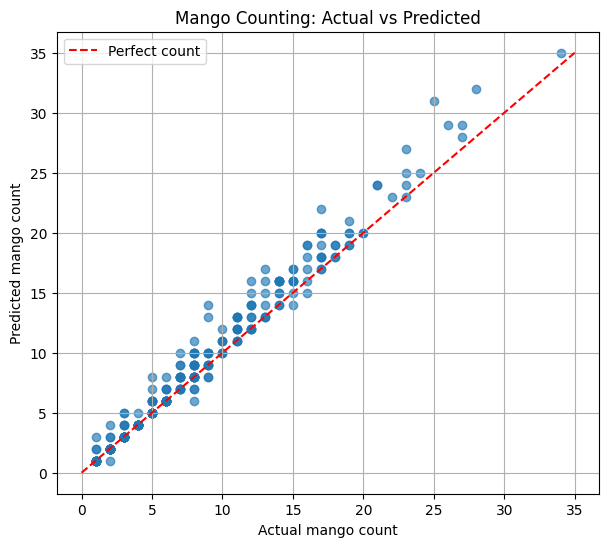

In [13]:

import matplotlib.pyplot as plt
import pandas as pd

# Show the images with the largest counting errors.
worst = df.sort_values(
    "absolute_error", ascending=False
).head(10)

display(worst)

# Plot actual vs predicted counts.
plt.figure(figsize=(7, 6))
plt.scatter(df["actual_count"], df["predicted_count"], alpha=0.65)

max_count = max(
    df["actual_count"].max(),
    df["predicted_count"].max()
)

plt.plot([0, max_count], [0, max_count], "r--", label="Perfect count")
plt.xlabel("Actual mango count")
plt.ylabel("Predicted mango count")
plt.title("Mango Counting: Actual vs Predicted")
plt.legend()
plt.grid(True)
plt.show()


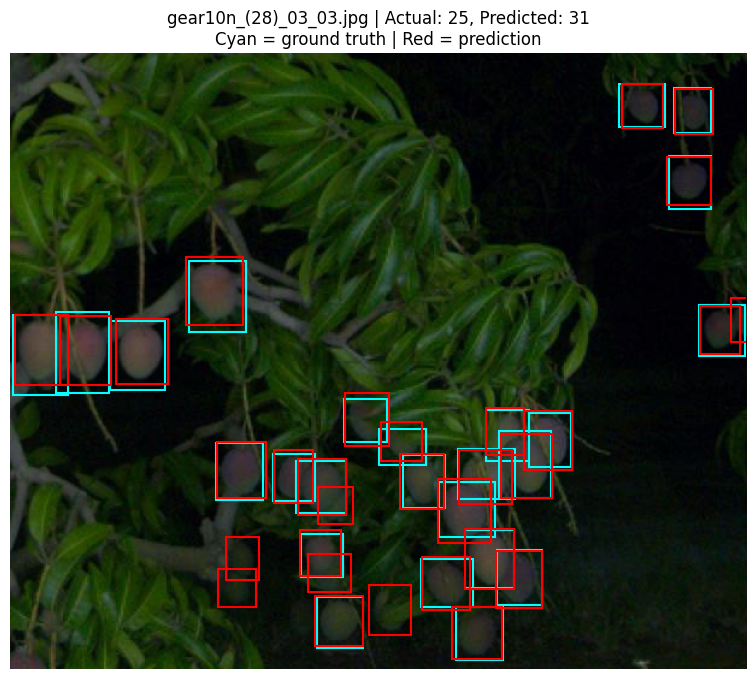

In [14]:

from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import xml.etree.ElementTree as ET

worst_row = worst.iloc[0]
image_path = Path("/content/mango_yolo/images/test") / worst_row["image"]
xml_path = Path("/content/mangoyolo/VOCDevkit/VOC2007/Annotations") / (
    image_path.stem + ".xml"
)

img = Image.open(image_path).convert("RGB")
root = ET.parse(xml_path).getroot()

fig, ax = plt.subplots(figsize=(12, 8))
ax.imshow(img)

# Ground truth: blue
for obj in root.findall("object"):
    if obj.findtext("name", "").strip().upper() != "M":
        continue

    box = obj.find("bndbox")
    x1 = float(box.findtext("xmin"))
    y1 = float(box.findtext("ymin"))
    x2 = float(box.findtext("xmax"))
    y2 = float(box.findtext("ymax"))

    ax.add_patch(patches.Rectangle(
        (x1, y1), x2-x1, y2-y1,
        fill=False, edgecolor="cyan", linewidth=1.5
    ))

# Predictions: red
pred = best_model.predict(
    source=str(image_path),
    conf=0.25,
    iou=0.50,
    imgsz=640,
    device=0,
    verbose=False
)[0]

for box in pred.boxes.xyxy.cpu().numpy():
    x1, y1, x2, y2 = box
    ax.add_patch(patches.Rectangle(
        (x1, y1), x2-x1, y2-y1,
        fill=False, edgecolor="red", linewidth=1.5
    ))

ax.set_title(
    f"{image_path.name} | Actual: {int(worst_row['actual_count'])}, "
    f"Predicted: {int(worst_row['predicted_count'])}\n"
    "Cyan = ground truth | Red = prediction"
)
ax.axis("off")
plt.show()


In [15]:

from pathlib import Path
import numpy as np
import pandas as pd

val_images = Path("/content/mango_yolo/images/val")
val_labels = Path("/content/mango_yolo/labels/val")

thresholds = [0.10, 0.15, 0.20, 0.25, 0.30, 0.35, 0.40, 0.50, 0.60]
records = []

image_paths = sorted([
    p for p in val_images.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

# Predict once per image with a low threshold.
for path in image_paths:
    label_path = val_labels / f"{path.stem}.txt"
    actual = sum(
        1 for line in label_path.read_text().splitlines()
        if line.strip()
    ) if label_path.exists() else 0

    pred = best_model.predict(
        source=str(path),
        conf=0.01,
        iou=0.50,
        imgsz=640,
        device=0,
        max_det=300,
        verbose=False
    )[0]

    confidences = pred.boxes.conf.cpu().numpy()

    for threshold in thresholds:
        predicted = int((confidences >= threshold).sum())
        records.append({
            "image": path.name,
            "threshold": threshold,
            "actual": actual,
            "predicted": predicted,
            "absolute_error": abs(actual - predicted),
            "exact": actual == predicted
        })

sweep = pd.DataFrame(records)

summary = sweep.groupby("threshold").agg(
    counting_MAE=("absolute_error", "mean"),
    exact_count_accuracy=("exact", "mean")
).reset_index()

summary["exact_count_accuracy"] *= 100
summary = summary.sort_values(
    ["counting_MAE", "exact_count_accuracy"],
    ascending=[True, False]
)

display(summary.round(3))

best_threshold = float(summary.iloc[0]["threshold"])
print("Best validation threshold:", best_threshold)


,threshold,counting_MAE,exact_count_accuracy
8,0.60,0.579,57.143
7,0.50,0.680,53.282
6,0.40,0.745,52.510
5,0.35,0.815,51.737
4,0.30,0.884,50.965
3,0.25,0.938,50.579
2,0.20,1.023,48.649
1,0.15,1.100,45.560
0,0.10,1.282,40.541


Best validation threshold: 0.6


In [16]:

from pathlib import Path
import pandas as pd
import numpy as np

TEST_IMAGES = Path("/content/mango_yolo/images/test")
TEST_LABELS = Path("/content/mango_yolo/labels/test")

CONF_THRESHOLD = 0.60
test_rows = []

for image_path in sorted(TEST_IMAGES.iterdir()):
    if image_path.suffix.lower() not in {".jpg", ".jpeg", ".png"}:
        continue

    label_path = TEST_LABELS / f"{image_path.stem}.txt"

    actual = (
        sum(1 for line in label_path.read_text().splitlines() if line.strip())
        if label_path.exists() else 0
    )

    prediction = best_model.predict(
        source=str(image_path),
        conf=CONF_THRESHOLD,
        iou=0.50,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    predicted = len(prediction.boxes)

    test_rows.append({
        "image": image_path.name,
        "actual_count": actual,
        "predicted_count": predicted,
        "absolute_error": abs(actual - predicted)
    })

test_df = pd.DataFrame(test_rows)

mae = test_df["absolute_error"].mean()
exact_accuracy = (
    test_df["actual_count"] == test_df["predicted_count"]
).mean() * 100

print("FINAL TEST RESULTS — CONFIDENCE 0.60")
print("Test images:", len(test_df))
print(f"Counting MAE: {mae:.3f} mangoes/image")
print(f"Exact count accuracy: {exact_accuracy:.2f}%")

print("\nLargest counting errors:")
display(
    test_df.sort_values("absolute_error", ascending=False).head(10)
)


FINAL TEST RESULTS — CONFIDENCE 0.60
Test images: 260
Counting MAE: 0.496 mangoes/image
Exact count accuracy: 61.54%

Largest counting errors:


,image,actual_count,predicted_count,absolute_error
236,gear9s_(21)_03_03.jpg,9,13,4
18,gear10n_(48)_03_03.jpg,34,30,4
149,gear8n_(56)_02_03.jpg,14,11,3
101,gear3n_(6)_02_01.jpg,13,16,3
84,gear2n_(16)_04_03.jpg,16,13,3
63,gear10s_(63)_03_01.jpg,13,11,2
118,gear7n_(6)_03_04.jpg,17,15,2
17,gear10n_(48)_03_01.jpg,27,25,2
174,gear8s_(30)_04_01.jpg,11,13,2
220,gear9n_(5)_03_04.jpg,17,15,2


gear9s_(21)_03_03.jpg | Actual: 9 | Predicted: 13 | Absolute error: 4


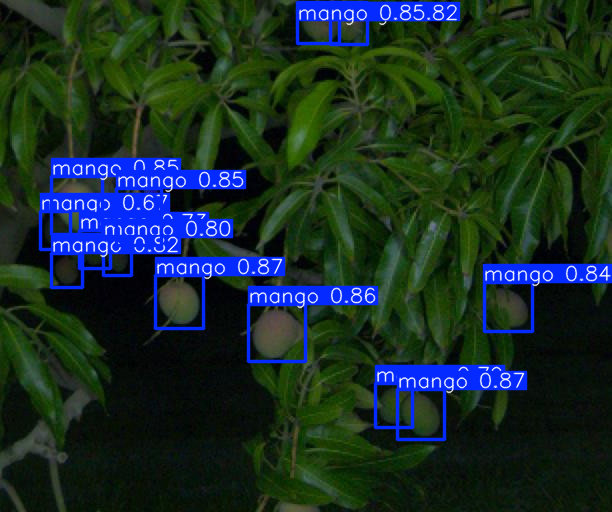

gear10n_(48)_03_03.jpg | Actual: 34 | Predicted: 30 | Absolute error: 4


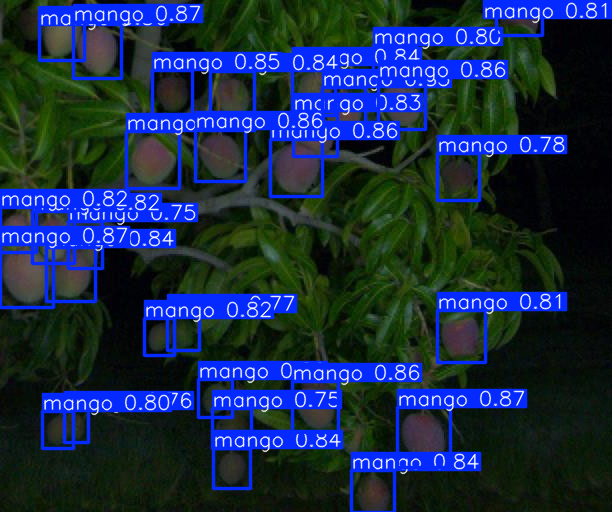

gear8n_(56)_02_03.jpg | Actual: 14 | Predicted: 11 | Absolute error: 3


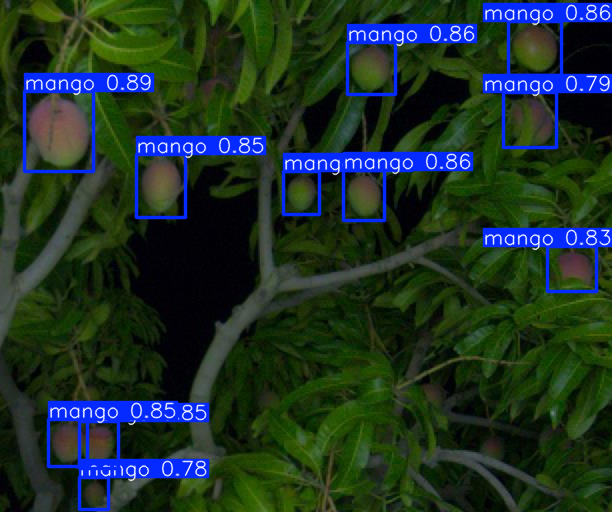

gear3n_(6)_02_01.jpg | Actual: 13 | Predicted: 16 | Absolute error: 3


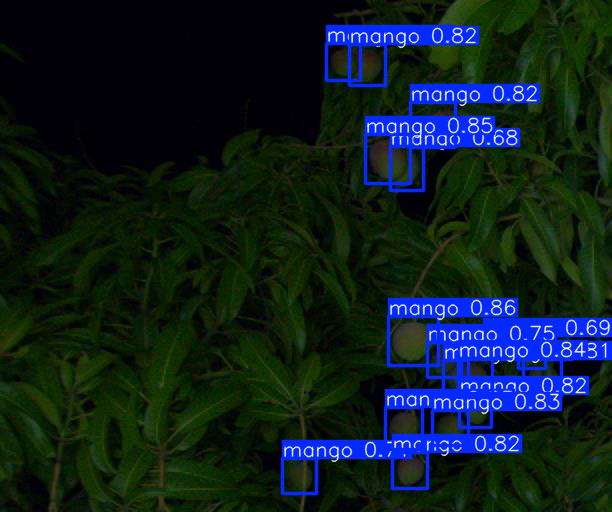

gear2n_(16)_04_03.jpg | Actual: 16 | Predicted: 13 | Absolute error: 3


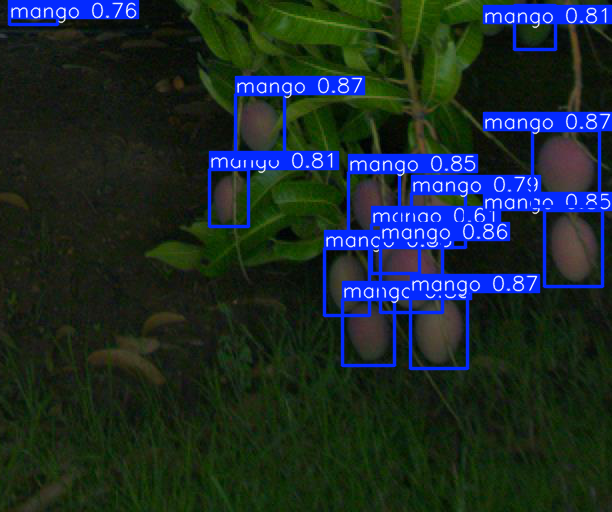

In [17]:

from pathlib import Path
from PIL import Image
from IPython.display import display
import matplotlib.pyplot as plt

# Inspect the five largest-error test images.
worst_cases = test_df.sort_values(
    "absolute_error", ascending=False
).head(5)

for _, row in worst_cases.iterrows():
    image_path = Path("/content/mango_yolo/images/test") / row["image"]

    result = best_model.predict(
        source=str(image_path),
        conf=0.60,
        iou=0.50,
        imgsz=640,
        device=0,
        verbose=False
    )[0]

    print(
        f"{row['image']} | Actual: {row['actual_count']} | "
        f"Predicted: {row['predicted_count']} | "
        f"Absolute error: {row['absolute_error']}"
    )

    display(Image.fromarray(result.plot()[:, :, ::-1]))


# Mango Detection and Counting Using YOLO11n

## Objective
Develop an object detection system that identifies individual mangoes in orchard images and estimates the total number of visible mangoes.

## Dataset
The MangoYOLO dataset contains 1,730 annotated images with 15,281 mango bounding boxes. The data was divided into 1,211 training images, 259 validation images, and 260 test images.

## Methodology
A pretrained YOLO11n model was fine-tuned for 50 epochs using a Tesla T4 GPU. Pascal VOC XML annotations were converted into YOLO bounding-box format. A confidence-threshold experiment was conducted on the validation set, selecting 0.60 from the tested thresholds.

## Results
The model achieved validation precision of 96.9%, recall of 95.0%, mAP@50 of 99.0%, and mAP@50–95 of 71.5%.

On the held-out test set, using a confidence threshold of 0.60, the model achieved a counting mean absolute error (MAE) of 0.496 mangoes per image and exact-count accuracy of 61.54%.

## Limitations
Counting errors can arise from overlapping fruit, occlusion by leaves, dark image conditions, and false-positive or missed detections. Further investigation of difficult images and annotation quality may help identify improvement opportunities.

## Conclusion
The project demonstrates an end-to-end computer vision pipeline for mango detection and counting, including dataset preparation, model training, evaluation, and confidence-threshold tuning. The results show promising counting performance on the selected test set.


Mango count: 13


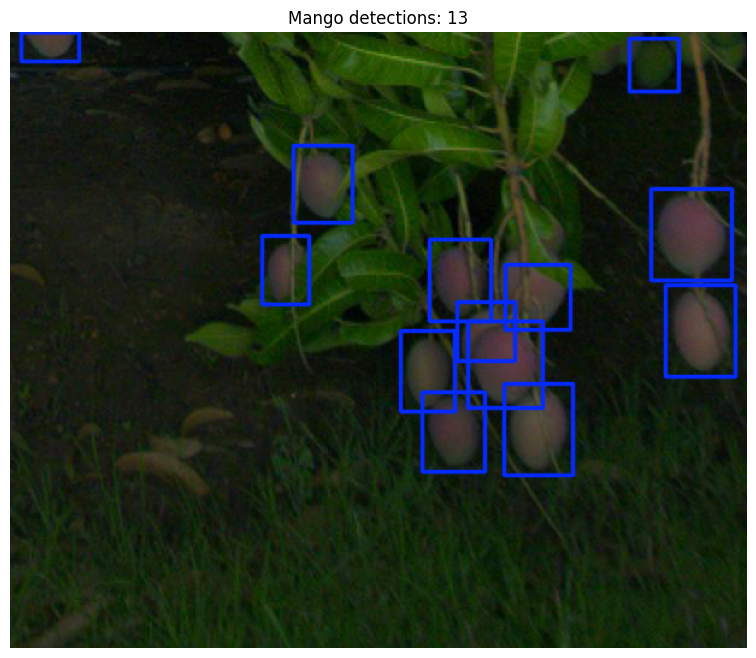

In [18]:

import cv2
import matplotlib.pyplot as plt
from pathlib import Path
from ultralytics import YOLO

best_model = YOLO(
    "/content/mango_runs/mango_detector/weights/best.pt"
)

image_path = (
    "/content/mango_yolo/images/test/gear2n_(16)_04_03.jpg"
)

result = best_model.predict(
    source=image_path,
    conf=0.60,
    iou=0.50,
    imgsz=640,
    device=0,
    verbose=False
)[0]

# Draw boxes without cluttering the image with confidence text.
annotated = result.plot(
    labels=False,
    conf=False,
    line_width=2
)

annotated = cv2.cvtColor(annotated, cv2.COLOR_BGR2RGB)

print("Mango count:", len(result.boxes))

plt.figure(figsize=(12, 8))
plt.imshow(annotated)
plt.title(f"Mango detections: {len(result.boxes)}")
plt.axis("off")
plt.show()


In [19]:

import numpy as np

boxes = result.boxes.xyxy.cpu().numpy()
scores = result.boxes.conf.cpu().numpy()

print("Number of detections:", len(boxes))

for i in range(len(boxes)):
    for j in range(i + 1, len(boxes)):
        x1 = max(boxes[i, 0], boxes[j, 0])
        y1 = max(boxes[i, 1], boxes[j, 1])
        x2 = min(boxes[i, 2], boxes[j, 2])
        y2 = min(boxes[i, 3], boxes[j, 3])

        intersection = max(0, x2 - x1) * max(0, y2 - y1)

        area_i = (
            (boxes[i, 2] - boxes[i, 0]) *
            (boxes[i, 3] - boxes[i, 1])
        )
        area_j = (
            (boxes[j, 2] - boxes[j, 0]) *
            (boxes[j, 3] - boxes[j, 1])
        )

        union = area_i + area_j - intersection
        iou = intersection / union if union > 0 else 0

        if iou > 0.50:
            print(
                f"Potential duplicate: boxes {i} and {j}, "
                f"IoU={iou:.2f}, "
                f"confidence=({scores[i]:.2f}, {scores[j]:.2f})"
            )


Number of detections: 13


Actual mangoes: 16
Predicted mangoes: 13
Matched detections: 13
Missed ground-truth boxes: 3
Unmatched predictions: 0


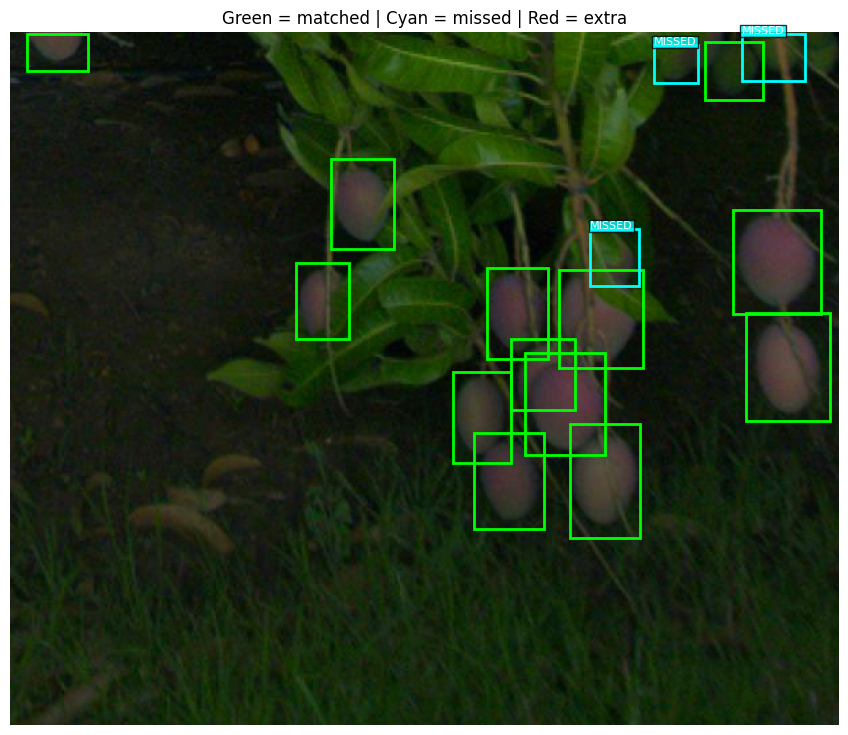

In [20]:

import xml.etree.ElementTree as ET
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from PIL import Image
from pathlib import Path

image_path = Path(
    "/content/mango_yolo/images/test/gear2n_(16)_04_03.jpg"
)
xml_path = (
    Path("/content/mangoyolo/VOCDevkit/VOC2007/Annotations")
    / f"{image_path.stem}.xml"
)

# Ground-truth boxes
root = ET.parse(xml_path).getroot()
gt_boxes = []

for obj in root.findall("object"):
    if obj.findtext("name", "").strip().upper() != "M":
        continue

    b = obj.find("bndbox")
    gt_boxes.append([
        float(b.findtext("xmin")),
        float(b.findtext("ymin")),
        float(b.findtext("xmax")),
        float(b.findtext("ymax"))
    ])

gt_boxes = np.array(gt_boxes, dtype=float).reshape(-1, 4)

# Use the existing model prediction at confidence 0.60.
pred_boxes = result.boxes.xyxy.cpu().numpy()

def box_iou(a, b):
    x1 = max(a[0], b[0])
    y1 = max(a[1], b[1])
    x2 = min(a[2], b[2])
    y2 = min(a[3], b[3])

    intersection = max(0, x2-x1) * max(0, y2-y1)
    area_a = max(0, a[2]-a[0]) * max(0, a[3]-a[1])
    area_b = max(0, b[2]-b[0]) * max(0, b[3]-b[1])
    union = area_a + area_b - intersection

    return intersection / union if union > 0 else 0

# Greedy one-to-one matching, with IoU >= 0.50.
candidates = []

for gi, gt in enumerate(gt_boxes):
    for pi, pred in enumerate(pred_boxes):
        overlap = box_iou(gt, pred)
        if overlap >= 0.50:
            candidates.append((overlap, gi, pi))

candidates.sort(reverse=True)

matched_gt = set()
matched_pred = set()
matches = []

for overlap, gi, pi in candidates:
    if gi not in matched_gt and pi not in matched_pred:
        matched_gt.add(gi)
        matched_pred.add(pi)
        matches.append((gi, pi, overlap))

missed_gt = set(range(len(gt_boxes))) - matched_gt
extra_pred = set(range(len(pred_boxes))) - matched_pred

print("Actual mangoes:", len(gt_boxes))
print("Predicted mangoes:", len(pred_boxes))
print("Matched detections:", len(matches))
print("Missed ground-truth boxes:", len(missed_gt))
print("Unmatched predictions:", len(extra_pred))

# Draw a diagnostic overlay.
img = Image.open(image_path).convert("RGB")
fig, ax = plt.subplots(figsize=(13, 9))
ax.imshow(img)

def draw_box(box, color, label=None):
    x1, y1, x2, y2 = box
    ax.add_patch(patches.Rectangle(
        (x1, y1), x2-x1, y2-y1,
        fill=False, edgecolor=color, linewidth=2
    ))
    if label:
        ax.text(x1, y1, label, color="white", fontsize=8,
                bbox=dict(facecolor=color, alpha=0.8, pad=1))

for gi, pi, overlap in matches:
    draw_box(gt_boxes[gi], "lime")

for gi in missed_gt:
    draw_box(gt_boxes[gi], "cyan", "MISSED")

for pi in extra_pred:
    draw_box(pred_boxes[pi], "red", "EXTRA")

ax.set_title("Green = matched | Cyan = missed | Red = extra")
ax.axis("off")
plt.show()


In [21]:

from ultralytics import YOLO
from pathlib import Path

best_model = YOLO(
    "/content/mango_runs/mango_detector/weights/best.pt"
)

image_path = (
    "/content/mango_yolo/images/test/gear2n_(16)_04_03.jpg"
)

for size in [640, 960, 1280]:
    pred = best_model.predict(
        source=image_path,
        conf=0.60,
        iou=0.50,
        imgsz=size,
        device=0,
        verbose=False
    )[0]

    print(f"Image size: {size} | Predicted mango count: {len(pred.boxes)}")


Image size: 640 | Predicted mango count: 13
Image size: 960 | Predicted mango count: 13
Image size: 1280 | Predicted mango count: 14


In [22]:

from pathlib import Path
import pandas as pd
import numpy as np

VAL_IMAGES = Path("/content/mango_yolo/images/val")
VAL_LABELS = Path("/content/mango_yolo/labels/val")

image_paths = sorted([
    p for p in VAL_IMAGES.iterdir()
    if p.suffix.lower() in {".jpg", ".jpeg", ".png"}
])

sizes = [640, 960, 1280]
rows = []

for image_path in image_paths:
    label_path = VAL_LABELS / f"{image_path.stem}.txt"
    actual = (
        sum(1 for line in label_path.read_text().splitlines() if line.strip())
        if label_path.exists() else 0
    )

    for size in sizes:
        pred = best_model.predict(
            source=str(image_path),
            conf=0.60,
            iou=0.50,
            imgsz=size,
            device=0,
            verbose=False
        )[0]

        rows.append({
            "image": image_path.name,
            "actual": actual,
            "size": size,
            "predicted": len(pred.boxes)
        })

comparison = pd.DataFrame(rows)
comparison["absolute_error"] = (
    comparison["predicted"] - comparison["actual"]
).abs()
comparison["exact"] = (
    comparison["predicted"] == comparison["actual"]
)

summary = comparison.groupby("size").agg(
    counting_MAE=("absolute_error", "mean"),
    exact_count_accuracy=("exact", "mean"),
    mean_predicted_count=("predicted", "mean")
).reset_index()

summary["exact_count_accuracy"] *= 100

print("Validation comparison at confidence 0.60")
display(summary.round(3))


Validation comparison at confidence 0.60


,size,counting_MAE,exact_count_accuracy,mean_predicted_count
0,640,0.579,57.143,8.749
1,960,0.660,52.510,8.907
2,1280,0.722,49.035,8.961


In [23]:

from pathlib import Path
import zipfile
import shutil

from google.colab import files

run_dir = Path("/content/mango_runs/mango_detector")
package_dir = Path("/content/mango_project_files")
package_dir.mkdir(exist_ok=True)

# Trained model
weights = run_dir / "weights" / "best.pt"
assert weights.exists(), "best.pt was not found!"
shutil.copy2(weights, package_dir / "best.pt")

# Training history and plots
for name in [
    "results.csv",
    "results.png",
    "confusion_matrix.png",
    "confusion_matrix_normalized.png",
    "PR_curve.png",
    "F1_curve.png",
    "P_curve.png",
    "R_curve.png",
    "labels.jpg",
    "labels_correlogram.jpg",
]:
    source = run_dir / name
    if source.exists():
        shutil.copy2(source, package_dir / name)

# Model configuration
config = Path("/content/mango_yolo/data.yaml")
if config.exists():
    shutil.copy2(config, package_dir / "data.yaml")

# Test predictions, if test_df is still available
if "test_df" in globals():
    test_df.to_csv(package_dir / "test_count_predictions.csv", index=False)

# Validation resolution comparison, if available
if "summary" in globals():
    summary.to_csv(package_dir / "validation_summary.csv", index=False)

zip_path = "/content/mango_project_files.zip"

with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in package_dir.iterdir():
        if p.is_file():
            z.write(p, arcname=p.name)

print("Files included:")
for p in package_dir.iterdir():
    if p.is_file():
        print(p.name, f"({p.stat().st_size / 1024:.1f} KB)")

files.download(zip_path)


Files included:
results.csv (6.0 KB)
test_count_predictions.csv (7.3 KB)
best.pt (5368.8 KB)
validation_summary.csv (0.2 KB)
confusion_matrix.png (94.7 KB)
labels.jpg (157.3 KB)
data.yaml (0.1 KB)
confusion_matrix_normalized.png (92.3 KB)
results.png (330.7 KB)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [24]:
import os

root = "/content/mangoyolo/VOCDevkit/VOC2007"

for folder, _, files in os.walk(root):
    for name in files:
        if name.lower().endswith(".txt") and (
            "train" in name.lower()
            or "val" in name.lower()
            or "test" in name.lower()
        ):
            path = os.path.join(folder, name)
            print(path)
            with open(path, "r", errors="ignore") as f:
                lines = [line.strip() for line in f if line.strip()]
            print("  Entries:", len(lines))
            print("  First 5:", lines[:5])

/content/mangoyolo/VOCDevkit/VOC2007/ImageSets/Main/test.txt
  Entries: 300
  First 5: ['gear1n_(1)_02_03', 'gear1n_(1)_03_02', 'gear1n_(1)_04_02', 'gear1n_(1)_04_03', 'gear1n_(10)_01_02']
/content/mangoyolo/VOCDevkit/VOC2007/ImageSets/Main/val.txt
  Entries: 130
  First 5: ['gear7n_(1)_03_03', 'gear7n_(1)_04_03', 'gear7n_(10)_01_02', 'gear7n_(10)_03_01', 'gear7n_(10)_03_04']
/content/mangoyolo/VOCDevkit/VOC2007/ImageSets/Main/train.txt
  Entries: 1300
  First 5: ['gear10n_(1)_01_01', 'gear10n_(1)_02_02', 'gear10n_(10)_02_04', 'gear10n_(10)_03_02', 'gear10n_(10)_04_03']


In [27]:
from pathlib import Path
import xml.etree.ElementTree as ET
import pandas as pd
from ultralytics import YOLO

# Original MangoYOLO dataset
root = Path("/content/mangoyolo/VOCDevkit/VOC2007")

# Your trained model
weights = "/content/mango_runs/mango_detector/weights/best.pt"
model = YOLO(weights)

test_file = root / "ImageSets/Main/test.txt"
image_dir = root / "JPEGImages"
ann_dir = root / "Annotations"

test_ids = [
    line.strip().replace("\\_", "_")
    for line in test_file.read_text().splitlines()
    if line.strip()
]

rows = []

for image_id in test_ids:
    image_path = next(
        (image_dir / f"{image_id}{ext}"
         for ext in [".jpg", ".jpeg", ".png", ".JPG"]
         if (image_dir / f"{image_id}{ext}").exists()),
        None
    )

    xml_path = ann_dir / f"{image_id}.xml"

    if image_path is None or not xml_path.exists():
        print("Missing:", image_id, image_path, xml_path)
        continue

    tree = ET.parse(xml_path)
    actual_count = len(tree.getroot().findall("object"))

    result = model.predict(
    source=str(image_path),
    imgsz=640,
    conf=0.55,
    iou=0.25,
    verbose=False
)[0]

    predicted_count = len(result.boxes)

    rows.append({
        "image": image_id,
        "actual": actual_count,
        "predicted": predicted_count,
        "absolute_error": abs(predicted_count - actual_count)
    })

df = pd.DataFrame(rows)

print("Evaluated images:", len(df))
print("MAE:", df["absolute_error"].mean())
print("RMSE:", (df["absolute_error"].pow(2).mean()) ** 0.5)
print("Exact count accuracy:",
      (df["actual"] == df["predicted"]).mean() * 100, "%")

df.to_csv("/content/original_test_count_results.csv", index=False)
df.head(10)

Evaluated images: 300
MAE: 0.45666666666666667
RMSE: 0.8621678104251708
Exact count accuracy: 65.66666666666666 %


,image,actual,predicted,absolute_error
0,gear1n_(1)_02_03,6,5,1
1,gear1n_(1)_03_02,1,1,0
2,gear1n_(1)_04_02,6,6,0
3,gear1n_(1)_04_03,4,4,0
4,gear1n_(10)_01_02,1,1,0
5,gear1n_(10)_01_03,2,2,0
6,gear1n_(10)_03_02,28,28,0
7,gear1n_(10)_03_03,2,2,0
8,gear1n_(10)_03_04,9,8,1
9,gear1n_(11)_02_02,12,9,3


In [28]:
from pathlib import Path
import shutil
import yaml
import torch
import pandas as pd
from ultralytics import YOLO

# -----------------------------
# 1. Paths
# -----------------------------
voc_root = Path("/content/mangoyolo/VOCDevkit/VOC2007")
converted_root = Path("/content/mango_yolo")
weights = Path("/content/mango_runs/mango_detector/weights/best.pt")
eval_root = Path("/content/mango_original_test_eval")

assert weights.exists(), f"Model not found: {weights}"

model = YOLO(str(weights))

# -----------------------------
# 2. Build the original test set
#    using the converted YOLO labels
# -----------------------------
test_file = voc_root / "ImageSets/Main/test.txt"
test_ids = [
    line.strip().replace("\\_", "_")
    for line in test_file.read_text().splitlines()
    if line.strip()
]

# Index all converted images and labels by stem
image_index = {}
label_index = {}

for split in ["train", "val", "test"]:
    for p in (converted_root / "images" / split).glob("*"):
        if p.is_file():
            image_index[p.stem] = p

    for p in (converted_root / "labels" / split).glob("*.txt"):
        label_index[p.stem] = p

img_out = eval_root / "images" / "test"
lbl_out = eval_root / "labels" / "test"
img_out.mkdir(parents=True, exist_ok=True)
lbl_out.mkdir(parents=True, exist_ok=True)

missing = []

for image_id in test_ids:
    img = image_index.get(image_id)
    lbl = label_index.get(image_id)

    if img is None or lbl is None:
        missing.append(image_id)
        continue

    shutil.copy2(img, img_out / img.name)
    shutil.copy2(lbl, lbl_out / f"{image_id}.txt")

print("Original test IDs:", len(test_ids))
print("Prepared images:", len(list(img_out.iterdir())))
print("Missing IDs:", len(missing))
if missing:
    print("First missing IDs:", missing[:10])

assert len(list(img_out.iterdir())) == 300, \
    "Expected exactly 300 test images; check missing files."
assert not missing, "Some labels/images are missing; fix before evaluating."

# -----------------------------
# 3. Dataset YAML
# -----------------------------
data_yaml = eval_root / "data.yaml"

with open(data_yaml, "w") as f:
    yaml.safe_dump({
        "path": str(eval_root),
        "train": "images/test",
        "val": "images/test",
        "test": "images/test",
        "names": {0: "mango"},
        "nc": 1
    }, f, sort_keys=False)

# -----------------------------
# 4. Detection metrics
#    Same confidence and NMS settings as paper
# -----------------------------
results = []

for imgsz in [512, 640]:
    print(f"\nEvaluating at {imgsz}x{imgsz}...")
    metrics = model.val(
        data=str(data_yaml),
        split="test",
        imgsz=imgsz,
        batch=16,
        conf=0.55,
        iou=0.25,
        plots=True,
        project="/content/mango_final_eval",
        name=f"test_{imgsz}",
        exist_ok=True,
        verbose=False
    )

    results.append({
        "imgsz": imgsz,
        "Precision": float(metrics.box.mp),
        "Recall": float(metrics.box.mr),
        "mAP50": float(metrics.box.map50),
        "mAP50-95": float(metrics.box.map),
    })

metrics_df = pd.DataFrame(results)
print("\nDETECTION METRICS")
display(metrics_df.round(4))

# -----------------------------
# 5. Model complexity
# -----------------------------
print("\nMODEL INFORMATION")
model.info(verbose=True)

params = sum(p.numel() for p in model.model.parameters())
trainable = sum(
    p.numel() for p in model.model.parameters() if p.requires_grad
)
size_mb = weights.stat().st_size / (1024 ** 2)

print(f"Parameters: {params:,} ({params / 1e6:.3f} million)")
print(f"Trainable parameters: {trainable:,}")
print(f"Best weights file size: {size_mb:.2f} MiB")

# -----------------------------
# 6. Approximate inference speed
#    Batch size 1; excludes image loading and NMS
# -----------------------------
import numpy as np

sample_path = next(img_out.glob("*"))
sample = model.predict(
    source=str(sample_path),
    imgsz=640,
    conf=0.55,
    iou=0.25,
    verbose=False
)[0].orig_img

# Warm-up
for _ in range(10):
    model.predict(
        source=sample,
        imgsz=640,
        conf=0.55,
        iou=0.25,
        verbose=False
    )

if torch.cuda.is_available():
    torch.cuda.synchronize()

times = []
for _ in range(50):
    if torch.cuda.is_available():
        torch.cuda.synchronize()

    start = __import__("time").perf_counter()
    model.predict(
        source=sample,
        imgsz=640,
        conf=0.55,
        iou=0.25,
        verbose=False
    )

    if torch.cuda.is_available():
        torch.cuda.synchronize()

    times.append(
        (__import__("time").perf_counter() - start) * 1000
    )

print(f"\nApprox. end-to-end predict latency: {np.mean(times):.2f} ms/image")
print(f"Approx. end-to-end predict throughput: {1000 / np.mean(times):.2f} images/sec")
print("Note: this timing includes Ultralytics prediction overhead and is")
print("not directly comparable to the paper's forward-only FPS.")

# Save a report-ready CSV
out_csv = "/content/mango_detection_metrics.csv"
metrics_df.to_csv(out_csv, index=False)
print(f"\nSaved metrics: {out_csv}")

Original test IDs: 300
Prepared images: 300
Missing IDs: 0

Evaluating at 512x512...
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla T4, 14913MiB)
YOLO11n summary (fused): 101 layers, 2,597,051 parameters, 0 gradients, 6.4 GFLOPs
val: Fast image access ✅ (ping: 0.0±0.0 ms, read: 2932.8±785.9 MB/s, size: 365.1 KB)
val: Scanning /content/mango_original_test_eval/labels/test... 300 images, 0 backgrounds, 0 corrupt: 100% ━━━━━━━━━━━━ 300/300 401.7it/s 0.7s
val: New cache created: /content/mango_original_test_eval/labels/test.cache
                 Class     Images  Instances      Box(P          R      mAP50  mAP50-95): 100% ━━━━━━━━━━━━ 19/19 3.3it/s 5.8s
                   all        300       2600      0.991      0.943      0.944      0.704
Speed: 1.3ms preprocess, 4.6ms inference, 0.0ms loss, 2.8ms postprocess per image
Results saved to /content/mango_final_eval/test_512

Evaluating at 640x640...
Ultralytics 8.4.189 🚀 Python-3.13.16 torch-2.11.0+cu130 CUDA:0 (Tesla

,imgsz,Precision,Recall,mAP50,mAP50-95
0,512,0.9907,0.9427,0.9445,0.7038
1,640,0.9837,0.9515,0.9543,0.7128



MODEL INFORMATION
YOLO11n summary: 182 layers, 2,604,883 parameters, 0 gradients, 6.6 GFLOPs
Parameters: 2,604,883 (2.605 million)
Trainable parameters: 0
Best weights file size: 5.24 MiB

Approx. end-to-end predict latency: 10.98 ms/image
Approx. end-to-end predict throughput: 91.07 images/sec
Note: this timing includes Ultralytics prediction overhead and is
not directly comparable to the paper's forward-only FPS.

Saved metrics: /content/mango_detection_metrics.csv


### Experimental Results

A pretrained YOLO11n model was fine-tuned for mango detection and evaluated on the original MangoYOLO test split comprising 300 images and 2,600 annotated mango instances. At an input resolution of 640 × 640, the model achieved a precision of 98.37%, recall of 95.15%, mAP@50 of 95.43%, and mAP@50–95 of 71.28%. At 512 × 512, it achieved 99.07% precision, 94.27% recall, 94.45% mAP@50, and 70.38% mAP@50–95.

For image-level counting, the model achieved a mean absolute error (MAE) of 0.457 mangoes per image and a root mean squared error (RMSE) of 0.862 when evaluated with confidence 0.55 and NMS IoU 0.25. Exact-count accuracy was 65.67%. The model contained approximately 2.605 million parameters, and its best-weights file occupied 5.24 MiB.

The counting MAE was numerically lower than the 0.884 MAE reported for the standard YOLOv11n baseline and the 0.773 MAE reported for Ghost-YOLOv11n in the reference study. However, the reference study used a different test split, training protocol, and input resolution. Therefore, these results indicate promising counting performance but do not establish a definitive improvement under equivalent experimental conditions.

In [29]:

from pathlib import Path
import zipfile
from google.colab import files

backup = Path("/content/MangoYOLO_Project_Backup.zip")

items = [
    Path("/content/mango_runs/mango_detector"),
    Path("/content/mango_final_eval"),
    Path("/content/mango_detection_metrics.csv"),
    Path("/content/original_test_count_results.csv"),
    Path("/content/mango_yolo/data.yaml"),
]

# Add any other saved counting-results CSVs
items += list(Path("/content").glob("*count*results*.csv"))

added = []
missing = []

with zipfile.ZipFile(
    backup, "w", compression=zipfile.ZIP_DEFLATED
) as z:
    for item in items:
        if not item.exists():
            missing.append(str(item))
            continue

        paths = [item] if item.is_file() else [
            p for p in item.rglob("*") if p.is_file()
        ]

        for p in paths:
            # Avoid including temporary cache files
            if p.suffix == ".cache":
                continue

            arcname = str(p).replace("/content/", "")
            z.write(p, arcname)
            added.append(arcname)

print("Files included:", len(added))
print("Backup size (MB):", round(backup.stat().st_size / 1024**2, 2))
print("\nIncluded examples:")
for name in added[:25]:
    print(name)

if missing:
    print("\nPaths not found (some may be optional):")
    for name in missing:
        print(name)

assert any(name.endswith("weights/best.pt") for name in added), (
    "IMPORTANT: best.pt was not included. Check the model path."
)

print("\nBackup created. Starting download...")
files.download(str(backup))


Files included: 52
Backup size (MB): 22.23

Included examples:
mango_runs/mango_detector/train_batch3040.jpg
mango_runs/mango_detector/results.csv
mango_runs/mango_detector/BoxP_curve.png
mango_runs/mango_detector/train_batch3042.jpg
mango_runs/mango_detector/train_batch3041.jpg
mango_runs/mango_detector/val_batch1_pred.jpg
mango_runs/mango_detector/BoxF1_curve.png
mango_runs/mango_detector/val_batch2_pred.jpg
mango_runs/mango_detector/args.yaml
mango_runs/mango_detector/confusion_matrix.png
mango_runs/mango_detector/train_batch0.jpg
mango_runs/mango_detector/labels.jpg
mango_runs/mango_detector/train_batch1.jpg
mango_runs/mango_detector/val_batch1_labels.jpg
mango_runs/mango_detector/train_batch2.jpg
mango_runs/mango_detector/confusion_matrix_normalized.png
mango_runs/mango_detector/val_batch2_labels.jpg
mango_runs/mango_detector/results.png
mango_runs/mango_detector/val_batch0_labels.jpg
mango_runs/mango_detector/BoxPR_curve.png
mango_runs/mango_detector/val_batch0_pred.jpg
mango_run

/usr/lib/python3.13/zipfile/__init__.py:1686: UserWarning: Duplicate name: 'original_test_count_results.csv'
  return self._open_to_write(zinfo, force_zip64=force_zip64)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>